# MNIST 손글씨 숫자 분류 (Classification)

PyTorch와 합성곱 신경망(CNN, Convolutional Neural Network)을 활용하여 $28 \times 28$ 해상도의 흑백 손글씨 숫자 이미지(MNIST 데이터셋, $0 \sim 9$)를 분류하는 전체 파이프라인을 실습합니다.

## 1. 각종 환경 변수 설정 및 시각화 헬퍼 함수 정의
* **경로 설정 (`DATA`, `RUNS`):** 실행 환경이 Google Colab(`/content` 디렉토리 존재 여부)인지 로컬 환경인지 자동 판별하여 데이터셋 저장 경로와 학습 결과(모델 가중치 및 로그) 저장 경로를 생성합니다.
* **연산 장치 설정 (`DEVICE`):** GPU(`cuda`) 사용 가능 여부를 확인하여 학습 및 추론에 사용할 디바이스를 할당합니다.
* **이미지 출력 함수 (`show_img`):** PIL 이미지를 주피터 노트북 셀에 출력할 때 지정된 너비(`width`)보다 크면 픽셀이 뭉개지지 않도록 최근접 이웃 보간법(`Image.NEAREST`)으로 리사이즈하여 선명하게 표시합니다.

In [1]:
# ==============================================================================
# [셀 1] 환경 변수(경로, GPU 디바이스) 설정 및 이미지 출력 유틸리티 함수 정의
# - Colab 및 로컬 환경에 맞춰 데이터(DATA)와 체크포인트 저장 폴더(RUNS)를 생성합니다.
# - GPU(CUDA) 가속 가능 여부를 확인하고, PIL 이미지를 노트북에 깔끔하게 출력하는
#   show_img() 함수를 정의합니다.
# ==============================================================================
from pathlib import Path
import torch
from IPython.display import display
from PIL import Image

DATA = Path("/content/mnist") if Path("/content").exists() else Path.cwd() / "mnist_data"
RUNS = Path("/content/mnist_runs") if Path("/content").exists() else Path.cwd() / "mnist_runs"
DATA.mkdir(parents=True, exist_ok=True)
RUNS.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__)
print("device", DEVICE)
if DEVICE.type == "cuda":
    print("gpu", torch.cuda.get_device_name(0))


def show_img(img, width=900):
    img = img.convert("RGB")
    w, h = img.size
    if w > width:
        img = img.resize((width, int(h * width / w)), Image.NEAREST)
    display(img)


torch 2.11.0+cu130
device cuda
gpu Tesla T4


## 2. 데이터셋 구축 및 샘플 시각화

* **데이터 분할 구성:**
  * 원본 학습 데이터(60,000장) $\rightarrow$ **학습용(Train): 55,000장** / **검증용(Validation): 5,000장** (`random_split` 활용)
  * **테스트용(Test): 10,000장** (최종 성능 평가용으로 분리 보관)
* **전처리 (`transforms.ToTensor()`):** $[0, 255]$ 범위의 픽셀 값을 $[0.0, 1.0]$ 범위의 실수형 텐서 `(1, 28, 28)`로 변환합니다.
* **재현성 보장 (`set_seed`):** Python `random` 및 PyTorch CPU/GPU 난수 시드를 `42`로 고정하여 데이터 분할과 가중치 초기화가 매 실행마다 동일하게 유지되도록 설정합니다.
* **타일 시각화 (`digit_to_pil`, `show_samples`):** $28 \times 28$ 텐서 이미지를 $84 \times 84$ 크기의 PIL 이미지로 확대한 뒤, 앞쪽 20장의 샘플을 $2 \times 10$ 격자(Grid) 캔버스에 이어 붙여 확인합니다.

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 449kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.06MB/s]
/tmp/ipykernel_3461/2850315380.py:48: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(arr, mode="L").resize((84, 84), Image.NEAREST)


train 55000 val 5000 test 10000


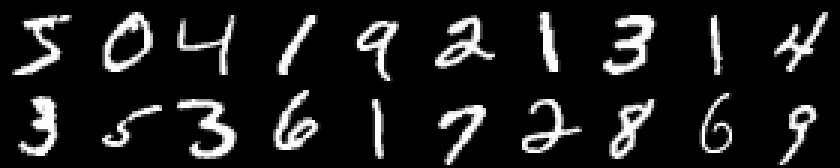

맨 앞 20 장. 왼쪽 위부터 오른쪽순으로 표시


In [2]:
# ==============================================================================
# [셀 2] 하이퍼파라미터 설정, MNIST 데이터셋 로드/분할 및 샘플 이미지 시각화
# - 학습 에폭(EPOCHS=5), 배치 크기(BATCH=128), 학습률(LR=1e-3), 시드(SEED=42)를 설정합니다.
# - MNIST 원본 학습셋(60,000장)을 Train(55,000장)과 Val(5,000장)로 분할하고,
#   배치 단위 공급을 위한 DataLoader(train/val/test)를 생성합니다.
# - 텐서를 이미지로 변환하여 첫 20장의 손글씨 샘플을 그리드 형태로 출력합니다.
# ==============================================================================
import random

import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

EPOCHS = 5
BATCH = 128
LR = 1e-3
SEED = 42


def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


tf = transforms.ToTensor()
DATA.mkdir(parents=True, exist_ok=True)
full_train = datasets.MNIST(DATA, train=True, download=True, transform=tf)
test_ds = datasets.MNIST(DATA, train=False, download=True, transform=tf)

set_seed(SEED)
n_val = 5000
n_train = len(full_train) - n_val
train_ds, val_ds = random_split(
    full_train,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED),
)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=0)
print("train", n_train, "val", n_val, "test", len(test_ds))


def digit_to_pil(t):
    arr = (t.squeeze().numpy() * 255).clip(0, 255).astype("uint8")
    return Image.fromarray(arr, mode="L").resize((84, 84), Image.NEAREST)


def show_samples(dataset, n=20, cols=10):
    cell = 84
    rows = (n + cols - 1) // cols
    canvas = Image.new("RGB", (cols * cell, rows * cell), (20, 20, 20))
    for i in range(n):
        img, y = dataset[i]
        tile = digit_to_pil(img).convert("RGB")
        r, c = divmod(i, cols)
        canvas.paste(tile, (c * cell, r * cell))
    show_img(canvas, width=840)
    print("맨 앞", n, "장. 왼쪽 위부터 오른쪽순으로 표시")


show_samples(full_train)


## 3. 합성곱 신경망(CNN) 모델 구축 (`DigitCNN`)
* **특징 추출부 (Feature Extractor):**
  * **`conv1` 블록:** `Conv2d(1 -> 32, kernel_size=3, padding=1)`로 공간 해상도($28 \times 28$)를 유지하며 32개 채널의 특징 맵을 추출한 뒤, `ReLU` 활성화와 `MaxPool2d(2)`를 거쳐 해상도를 절반($14 \times 14$)으로 축소합니다. $\rightarrow$ `(B, 32, 14, 14)`
  * **`conv2` 블록:** `Conv2d(32 -> 64, kernel_size=3, padding=1)`와 `ReLU`를 거친 후, 다시 `MaxPool2d(2)`로 해상도를 절반($7 \times 7$)으로 줄입니다. $\rightarrow$ `(B, 64, 7, 7)`
* **분류기 (Classifier):**
  * **`fc` 블록:** 3차원 특징 맵을 1차원 벡터($64 \times 7 \times 7 = 3,136$차원)로 평탄화(`Flatten`)한 뒤, 은닉층(`Linear(3136 -> 128)` + `ReLU`)을 거쳐 최종 10개 숫자 클래스($0 \sim 9$)에 대한 로짓(`logits`, `(B, 10)`)을 출력합니다.
* **차원 및 파라미터 검증 (`show_cnn_shapes`):** 더미 텐서 `(1, 1, 28, 28)`을 통과시켜 계층별 출력 텐서 형태(Shape)와 총 학습 파라미터 수(421,642개)를 확인합니다.

In [3]:
# ==============================================================================
# [셀 3] CNN 모델(DigitCNN) 클래스 정의 및 계층별 텐서 Shape / 파라미터 수 확인
# - 2개의 합성곱+풀링 블록(conv1, conv2)과 완전연결 분류기(fc)로 구성된 CNN을 정의합니다.
# - 더미 입력(1, 1, 28, 28)을 주입하여 각 스테이지 통과 후의 텐서 차원 변화와
#   전체 학습 가능한 파라미터 개수를 출력합니다.
# ==============================================================================
from torch import nn


class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        return self.fc(x)


def show_cnn_shapes(model, h=28, w=28):
    model.eval()
    x = torch.zeros(1, 1, h, w)
    with torch.no_grad():
        c1 = model.conv1(x)
        c2 = model.conv2(c1)
        logits = model.fc(c2)
    for name, t in (("input", x), ("conv1+pool", c1), ("conv2+pool", c2), ("logits", logits)):
        print(f"{name:12s} {tuple(t.shape)}")
    n = sum(p.numel() for p in model.parameters())
    print(f"파라미터 {n:,}")


show_cnn_shapes(DigitCNN())


input        (1, 1, 28, 28)
conv1+pool   (1, 32, 14, 14)
conv2+pool   (1, 64, 7, 7)
logits       (1, 10)
파라미터 421,642


## 4. 모델 학습, 체크포인트 저장 및 테스트셋 최종 평가
* **손실 함수 및 옵티마이저:** 다중 클래스 분류를 위한 `CrossEntropyLoss()`와 가중치 감쇠(Weight Decay)가 결합된 `AdamW(lr=1e-3)` 옵티마이저를 사용합니다.
* **에폭 실행 함수 (`run_epoch`):** `train` 불리언 인자에 따라 학습 모드(`train=True`)와 검증 모드(`train=False`)를 하나의 함수에서 깔끔하게 처리합니다. `torch.set_grad_enabled(train)`을 통해 학습 시에만 역전파 및 가중치 갱신을 수행합니다.
* **최고 성능 모델 저장 (`best.pt`) 및 이력 기록 (`history.json`):** 매 에폭마다 검증 정확도(`va_acc`)를 비교하여 최고 기록을 경신할 때마다 `best.pt`에 모델 가중치(`state_dict`)를 저장하고, 에폭별 손실/정확도 추이를 JSON 파일로 기록합니다.
* **최종 테스트셋 평가 (`eval_split`):** 학습 완료 후 가장 검증 성능이 높았던 `best.pt` 가중치를 다시 불러와, 학습에 전혀 사용되지 않은 테스트셋(10,000장)에 대해 **전체 정확도(`acc`)**와 **숫자 클래스별(0~9) 정확도(`per_class`)**를 산출합니다.

In [4]:
# ==============================================================================
# [셀 4] 모델 학습/검증 루프 실행, Best 체크포인트 저장 및 테스트셋 정량 평가
# - CrossEntropyLoss와 AdamW 옵티마이저를 사용하여 EPOCHS(5회) 동안 학습합니다.
# - 매 에폭 검증셋(val_loader) 정확도를 측정하여 최고 성능 모델을 best.pt로 저장합니다.
# - 학습 종료 후 best.pt를 로드하여 테스트셋(10,000장) 전체 및 클래스별 정확도를 평가합니다.
# ==============================================================================
import json

import torch
from torch import nn

set_seed(SEED)
model = DigitCNN().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
RUNS.mkdir(parents=True, exist_ok=True)


def accuracy(logits, y):
    return (logits.argmax(1) == y).float().mean().item()


def run_epoch(model, loader, train):
    model.train(train)
    total_loss, total_acc, n = 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
        bs = y.size(0)
        total_loss += loss.item() * bs
        total_acc += accuracy(logits.detach(), y) * bs
        n += bs
    return total_loss / n, total_acc / n


@torch.no_grad()
def eval_split(model, loader):
    model.eval()
    n_ok = n = 0
    per_ok = [0] * 10
    per_n = [0] * 10
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        pred = model(x).argmax(1)
        n += y.size(0)
        n_ok += int((pred == y).sum().item())
        for t, p in zip(y.tolist(), pred.tolist()):
            per_n[t] += 1
            if t == p:
                per_ok[t] += 1
    per = {str(i): (per_ok[i] / per_n[i] if per_n[i] else 0.0) for i in range(10)}
    return {"acc": n_ok / n if n else 0.0, "n": n, "per_class": per}


best_acc = -1.0
history = []
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, True)
    va_loss, va_acc = run_epoch(model, val_loader, False)
    history.append(
        {
            "epoch": epoch,
            "train_loss": round(tr_loss, 4),
            "train_acc": round(tr_acc, 4),
            "val_loss": round(va_loss, 4),
            "val_acc": round(va_acc, 4),
        }
    )
    print(
        f"epoch {epoch:03d}  train loss {tr_loss:.4f} acc {tr_acc:.3f}  "
        f"val loss {va_loss:.4f} acc {va_acc:.3f}"
    )
    if va_acc >= best_acc:
        best_acc = va_acc
        torch.save({"model": model.state_dict()}, RUNS / "best.pt")

(RUNS / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
print("saved", RUNS / "best.pt", "best_val_acc", round(best_acc, 4))

ckpt = torch.load(RUNS / "best.pt", map_location="cpu", weights_only=True)
model.load_state_dict(ckpt["model"])
print("held_out_test", eval_split(model, test_loader))


epoch 001  train loss 0.2638 acc 0.920  val loss 0.0790 acc 0.977
epoch 002  train loss 0.0593 acc 0.982  val loss 0.0543 acc 0.984
epoch 003  train loss 0.0408 acc 0.987  val loss 0.0509 acc 0.985
epoch 004  train loss 0.0315 acc 0.990  val loss 0.0586 acc 0.981
epoch 005  train loss 0.0255 acc 0.992  val loss 0.0372 acc 0.990
saved /content/mnist_runs/best.pt best_val_acc 0.9896
held_out_test {'acc': 0.9901, 'n': 10000, 'per_class': {'0': 0.9979591836734694, '1': 0.9991189427312775, '2': 0.9903100775193798, '3': 0.9891089108910891, '4': 0.9918533604887984, '5': 0.9899103139013453, '6': 0.9832985386221295, '7': 0.9922178988326849, '8': 0.9856262833675564, '9': 0.9801783944499505}}


## 5. 추론 결과 및 오분류(Misclassified) 샘플 시각화

* **개별 예측 타일 생성 (`labeled_tile`):**
  * 각 이미지 하단에 모델의 예측값(`p{pred}`)과 실제 정답(`gt{gt}`) 텍스트를 캡션으로 표시합니다.
  * 정답을 맞춘 경우 녹색 텍스트로 표시하고, **틀린 경우(오분류) 붉은색 배경 캡션과 빨간색 테두리(`outline=(220, 40, 40)`)**를 둘러 시각적으로 즉시 구분할 수 있게 합니다.
* **결과 비교 출력 (`show_grid`):**
  1. **테스트셋 앞 20장 (`preview`):** 일반적인 추론 성능을 확인합니다.
  2. **틀린 샘플 모음 (`wrong`, 최대 20장):** 모델이 어떤 형태의 악필이나 모호한 숫자에서 혼동을 겪는지 오답 노트 형태로 모아 분석합니다.

/tmp/ipykernel_3461/2850315380.py:48: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(arr, mode="L").resize((84, 84), Image.NEAREST)


테스트 앞 20장


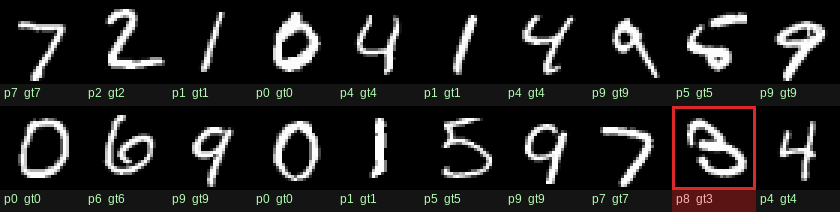


틀린 샘플 (최대 20장)


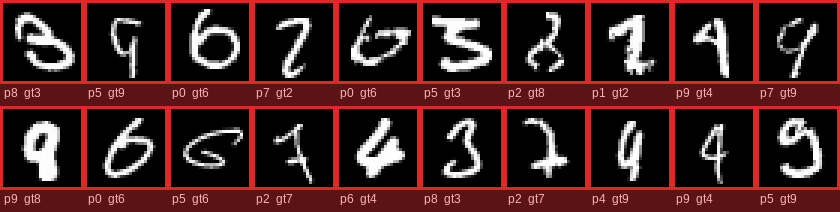

In [5]:
# ==============================================================================
# [셀 5] 저장된 Best 모델 로드 후 테스트셋 추론 결과 및 오분류 샘플 시각화
# - 예측값(p)과 실제 정답(gt)을 이미지 하단에 라벨링하고, 오답인 경우 빨간 테두리로
#   강조하는 labeled_tile() 함수를 정의합니다.
# - 테스트셋 첫 20장의 예측 결과와, 모델이 틀린 오분류 샘플(최대 20장)을 각각 출력합니다.
# ==============================================================================
from PIL import ImageDraw, ImageFont


def font(size):
    for path in (
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    ):
        try:
            return ImageFont.truetype(path, size)
        except OSError:
            continue
    return ImageFont.load_default()


def labeled_tile(img, pred, gt, size=84):
    ok = pred == gt
    tile = digit_to_pil(img).convert("RGB").resize((size, size), Image.NEAREST)
    canvas = Image.new("RGB", (size, size + 22), (20, 20, 20) if ok else (90, 20, 20))
    canvas.paste(tile, (0, 0))
    draw = ImageDraw.Draw(canvas)
    color = (180, 255, 180) if ok else (255, 180, 180)
    draw.text((4, size + 2), f"p{pred}  gt{gt}", fill=color, font=font(12))
    if not ok:
        draw.rectangle([0, 0, size - 1, size - 1], outline=(220, 40, 40), width=3)
    return canvas


def show_grid(items, cols=10, title=""):
    if not items:
        print(title, "없음")
        return
    cell_w, cell_h = items[0].size
    rows = (len(items) + cols - 1) // cols
    canvas = Image.new("RGB", (cols * cell_w, rows * cell_h), (12, 12, 12))
    for i, tile in enumerate(items):
        r, c = divmod(i, cols)
        canvas.paste(tile, (c * cell_w, r * cell_h))
    if title:
        print(title)
    show_img(canvas, width=min(980, cols * cell_w))


model = DigitCNN()
model.load_state_dict(torch.load(RUNS / "best.pt", map_location="cpu", weights_only=True)["model"])
model.eval()
model.to(DEVICE)

preview = []
wrong = []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        pred = model(x).argmax(1).cpu()
        for i in range(x.size(0)):
            tile = labeled_tile(x[i].cpu(), int(pred[i]), int(y[i]))
            if len(preview) < 20:
                preview.append(tile)
            if int(pred[i]) != int(y[i]) and len(wrong) < 20:
                wrong.append(tile)
        if len(preview) >= 20 and len(wrong) >= 20:
            break

show_grid(preview, title="테스트 앞 20장")
print()
show_grid(wrong, title="틀린 샘플 (최대 20장)")
